# Project: Whale migration Analysis

**Goal:** to see which regions have the most observations.

**Data:** Movebank (open source).

In [20]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [21]:
import pandas as pd

I loaded the data on the movements of blue whales from an open resource, Movebank, from East Antarctica to the sector of the Southern Ocean.
In CSV file format.

In [22]:
df = pd.read_csv("/content/drive/MyDrive/Colab_Notebooks/Antarctic blue whales, east Antarctic sector of the Southern Ocean.csv")

After opening the file, I displayed the first 5 rows of the table to see what the data looks like and what columns it contains.

In [23]:
df.head()

,event-id,visible,timestamp,location-long,location-lat,argos:calcul-freq,argos:iq,argos:lc,argos:location-algorithm,argos:nb-mes,argos:sat-id,sensor-type,individual-taxon-canonical-name,tag-local-identifier,individual-local-identifier,study-name
0,24174715697,True,2013-03-08 05:45:10.000,169.011,-64.172,401677626.0,8.0,B,least squares,1,K,argos-doppler-shift,Balaenoptera musculus,121205,121205,"Antarctic blue whales, east Antarctic sector o..."
1,24174715698,True,2013-03-08 06:08:52.000,NaN,NaN,NaN,NaN,NaN,least squares,2,M,argos-doppler-shift,Balaenoptera musculus,121205,121205,"Antarctic blue whales, east Antarctic sector o..."
2,24174715699,True,2013-03-08 06:33:36.000,NaN,NaN,NaN,NaN,NaN,least squares,1,N,argos-doppler-shift,Balaenoptera musculus,121205,121205,"Antarctic blue whales, east Antarctic sector o..."
3,24174715700,True,2013-03-08 07:26:05.000,NaN,NaN,NaN,NaN,NaN,least squares,3,K,argos-doppler-shift,Balaenoptera musculus,121205,121205,"Antarctic blue whales, east Antarctic sector o..."
4,24174715701,True,2013-03-08 07:47:02.000,169.074,-64.187,401677544.0,NaN,A,least squares,3,M,argos-doppler-shift,Balaenoptera musculus,121205,121205,"Antarctic blue whales, east Antarctic sector o..."


I counted the total number of rows and columns in the original table.
It turned out to be 835 rows and 16 columns.

In [24]:
df.shape

(835, 16)

I checked each column for missing values and summed up the resulting missing values together. For further analysis.

In [25]:
df.isnull().sum()

,0
event-id,0
visible,0
timestamp,0
location-long,27
location-lat,27
argos:calcul-freq,28
argos:iq,302
argos:lc,27
argos:location-algorithm,0
argos:nb-mes,0


I removed rows with empty values only in the specified two columns ['location-long', 'location-lat'] to make them cleaner.

I checked the new number of rows and columns using df_clean.shape.

The result was: (808, 16)

In [26]:
df_clean = df.dropna(subset=['location-long', 'location-lat']).copy()
df_clean.shape

(808, 16)

I imported new values using the matplotlib library to create my own visualization of the updated table.

In [27]:
import matplotlib.pyplot as plt

I created an empty canvas with a size of 10 by 6.

I connected the two columns I was interested in with data from location-long, location-lat.

And reproduced their output as points with a size of 10.

I named the horizontal axis of the table "Longitude", and gave the vertical one the name "Latitude", with the title "Whale observation".

And I displayed the resulting visual of the table on the screen.
Now we can see where blue whales swam most often.

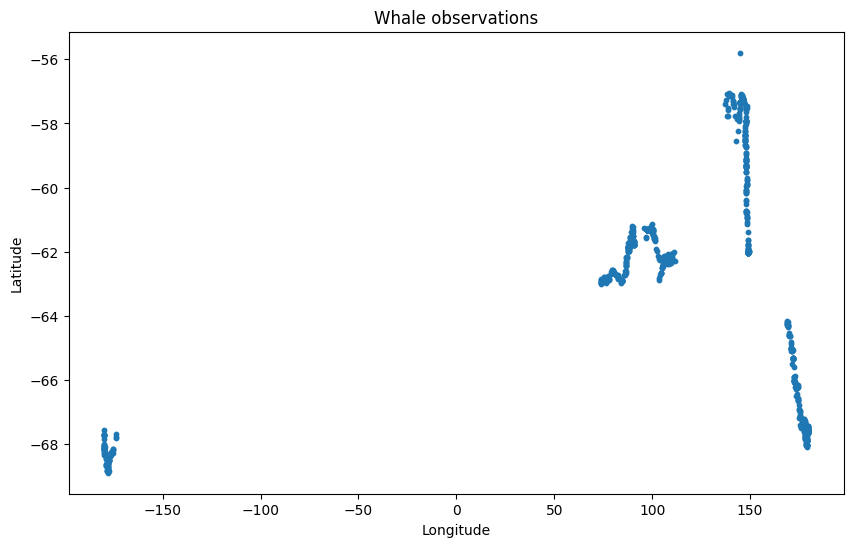

In [28]:
plt.figure(figsize=(10, 6))
plt.scatter(df_clean['location-long'], df_clean['location-lat'], s=10)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Whale observations')
plt.show()

I created two new columns long_round and lat_round to store the already rounded numbers from location-long and location-lat in them.

In [29]:
df_clean['long_round'] = df_clean['location-long'].round()

In [30]:
df_clean['lat_round'] = df_clean['location-lat'].round()

I created a new cell to output into a list the already grouped rows with the same longitude and latitude into one group.

From this we see the coordinates of the square on the left side, and on the right side how many observations there are.

In [31]:
counts = df_clean.groupby(['long_round', 'lat_round']).size()

In [32]:
counts

long_round  lat_round
-180.0      -68.0        30
-179.0      -69.0         4
            -68.0         4
-178.0      -69.0        25
            -68.0         1
                         ..
 178.0      -67.0        12
 179.0      -68.0        43
            -67.0         9
 180.0      -68.0        24
            -67.0         2
Length: 94, dtype: int64

I sort the data numbers in order from largest to smallest.
And I output the first 10 rows.

Thus obtaining the top 10 squares where the largest number of whale observations were conducted.

In [33]:
counts.sort_values(ascending = False).head(10)

long_round  lat_round
 88.0       -62.0        57
 179.0      -68.0        43
 149.0      -62.0        37
 148.0      -58.0        32
            -59.0        31
-180.0      -68.0        30
-178.0      -69.0        25
 146.0      -57.0        25
 178.0      -68.0        24
 180.0      -68.0        24
dtype: int64

## Conclusion

I analyzed 808 whale observations from the Movebank database.

Most observations are concentrated in several specific areas of the Southern Ocean, near the coast of Antarctica:

- 88 / -62 (57 observations) — south of Australia
- 179 / -68 (43 observations) — near the 180° meridian
- 149 / -62 (37 observations) — south of Tasmania
- 148 / -58 (32 observations) — south of Australia

This suggests that blue whales prefer specific areas rather than being evenly distributed across the ocean.

## What could be improved

- Add real region names instead of coordinates (e.g., "Davis Sea" instead of "88 / -62")
- Analyze each whale separately (the file contains two individual IDs: 121205 and 123223)
- Build a map with colored squares based on the number of observations